# Connectome Spectrum Transform from a template

If the patient's tractography is unavailable, you can infer a structural connectome using a connectome atlas. In this project, we use the MultiConn atlas from [Alemán-Gómez et. al 2022](https://www.nature.com/articles/s41597-022-01624-8).

The connectome in this context represents the structural connections between sources in our source space. These include white matter tracts (long-range connections) inferred from an atlas, and gray matter tracts (short-range connections) inferred from a specific method.

- **White Matter Tracts**: Two sources are connected if the brain regions they belong to are connected according to the MultiConn atlas. This requires segmenting the subject's brain using MultiConn's parcellation, which was done in `./parcellation.ipynb`. The parcellation results are stored in `../dataset/spike_sample/derivatives/mindmap/subject/parc/`.
- **Gray Matter Tracts**: Two sources are connected if their geodesic distance is smaller than a user-defined threshold.

Once the connectome for the source space is obtained, the Connectome Spectrum Transform is performed by computing the graph signal transform of the connectome.

## 📦 Imports

In [19]:
from pathlib import Path
import os

import mindmap as mm

import numpy as np
import scipy as sp
import pandas as pd
import pygsp

import matplotlib.pyplot as plt 

## 🧠 Data

In [20]:
sub = "sub-pat10"
mm.io.read_config("../configurations/spike.yml", env=True)

# directories
mm_dir = Path(os.environ["MM_DIR"])

# data
data = mm.io.read_dataset(sub, "src", "parc", "white")
std  = mm.io.read_standards("conn")

# parameters
cons_thresh = 40       # consistency threshold
len_thresh  = 25       # fiber length threshold
n_thresh    = 20       # number of streamlines threshold
dmax        = 0.010    # maximum distance for short distance connection

#### Additional utility

In [6]:
def correct_labels(labels, sources, parcel):
    """
    Correct labels that misplace left and right hemisphere dipoles because the parcellation is not perfect.
    """
    # map to switch from label id to label name
    clut = parcel.get_clut()
    map  = pd.Series(clut["Label name"].values, index=clut["#No."]).to_dict()
    
    label_names = [map[id] for id in labels]

    # left/right hemisphere seperation
    split = len(sources[0]["vertno"])

    # switch 'lh' labels in right hemisphere to 'rh' homologue and vice virsa
    label_names[:split] = [l.replace("-rh-", "-lh-") for l in label_names[:split]]
    label_names[split:] = [l.replace("-lh-", "-rh-") for l in label_names[split:]]

    # convert back to lable ids
    new_labels = [list(map.keys())[list(map.values()).index(n)] for n in label_names]

    return new_labels

def plot(connectome, name="Connectome"):
    degree = np.sum(connectome, axis=1)

    fig, axs = plt.subplots(1,2, figsize=(12,5))

    axs[0].matshow(connectome, cmap="Blues")
    axs[0].set_title(name)
    axs[0].set_xlabel("Dipoles")
    axs[0].set_ylabel("Dipoles")

    axs[1].hist(degree, bins=100, color="skyblue")
    axs[1].set_title("Degree Distribution")
    axs[1].set_xlabel("Degree")
    axs[1].set_ylabel("Frequency")

    plt.tight_layout()
    plt.show()

## Infere Subject Connectome from Atlas Connectome
⚙️ <font color=green>**Threshold Atlas**</font>: First we threshold the atlas to our liking. Threshold values were chosen to produce the cleanest harmonics.

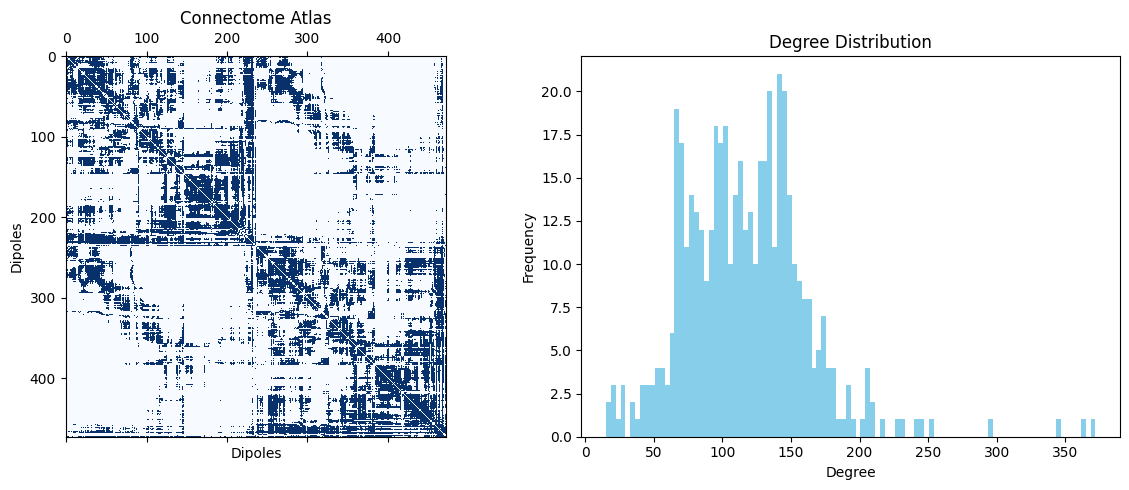

In [7]:
# label sources
points = [s["rr"][s["vertno"]] for s in data["src"]]
points = np.concatenate(points)*1000                  # in surface RAS space in [mm].  !!!!!!! Add the cras translation now that I now  !!!!!!!
labels = data["parc"].label_points(points, id=True)   # brain region label for each source.

# some left/right regions are very close and get mixed up
labels = correct_labels(labels, data["src"], data["parc"])

# convert atlas to binary adjacency matrix
consistency = std["conn"]["matrices"]["consistency"]
length      = std["conn"]["matrices"]["length"]
number      = std["conn"]["matrices"]["numbStlines"]

sc_atlas = np.bitwise_and(
    consistency[:,:] > cons_thresh, 
    length[:,:] > len_thresh,
    number[:,:] > n_thresh,
)

plot(sc_atlas, name="Connectome Atlas")

⚙️ <font color=green>**Infer White Matter Tracks from Atlas**</font>: Create connections between sources as follows: let $i$ be a source in region A and $j$ be a source in region B. If the atlas indicates that region A is connected to region B, then connect $i$ to $j$.

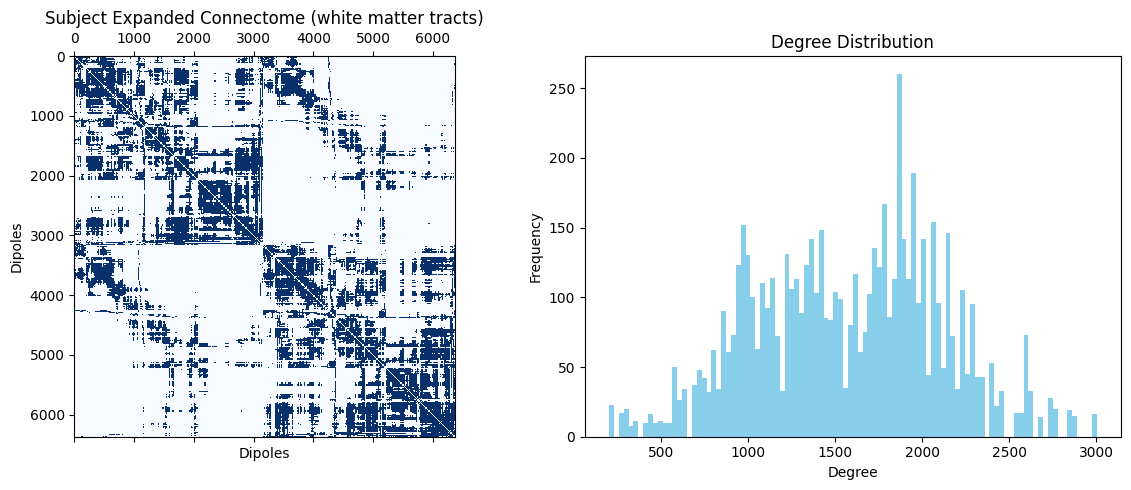

In [12]:
N = points.shape[0]
sc = np.zeros((N,N))

for i, l in enumerate(labels):
    connected_regions = np.argwhere(sc_atlas[l-1]==1)+1
    connections = np.isin(labels, connected_regions)
    sc[i] = connections 

sc = sp.sparse.csc_array(sc>0)

# sort for plotting
idx = np.argsort(labels)
viz = sc.todense()[idx]
viz = viz[:,idx]
plot(viz, name="Subject Expanded Connectome (white matter tracts)")

⚙️ <font color=green>**Infer Gray Matter Tracks from Distance**</font>: If sources $i$ and $j$ are less than dmax distance apart, then connect $i$ and $j$.

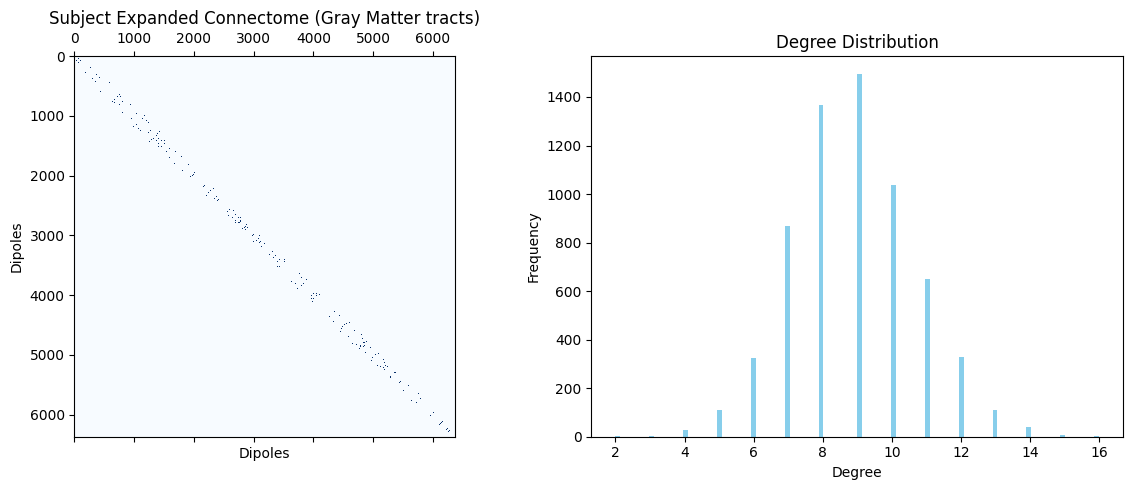

In [13]:
gmt = mm.utils.interpol_gm_tracks(data["src"], dmax)
plot(gmt.todense(), "Subject Expanded Connectome (Gray Matter tracts)")

⚙️ <font color=green>**Combine White Matter Tracks and Gray Matter Tracks**</font>

In [14]:
sc = sc + gmt 
sc = sc.astype(bool).astype(int)

#### <font color=yellow>🌟</font> Visualize Final Connectome

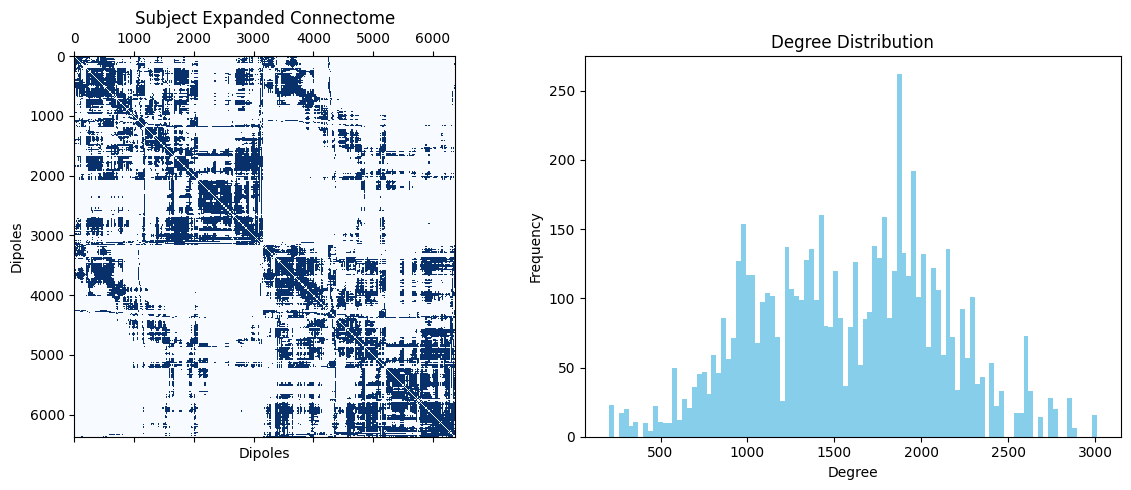

In [15]:
idx = np.argsort(labels)
viz = sc.todense()[idx]
viz = viz[:,idx]
plot(viz, "Subject Expanded Connectome")

## Connectome Spectrum Transform

⚙️ <font color=green>**Compute the Connectome Spectrum Transform (CST)**</font>: The CST is simply the Fourier Graph Transform of the connectome. The harmonics (or eigenvectors) of this transform are characteristic of the connectome. Visualize them to assess the quality of the CST.

In [16]:
coords = [s["rr"][s["vertno"]] for s in data["src"]]
G = pygsp.graphs.Graph(sc.todense(), lap_type="normalized", coords=coords)
G.compute_fourier_basis()
cst = G.U.T

2024-10-30 13:16:42,211:[WARNING](pygsp.graphs.graph.compute_fourier_basis): Computing the full eigendecomposition of a large matrix (6372 x 6372) may take some time.


#### <font color=yellow>🌟</font> Visualize the harmonics

In [17]:
harmonic = cst[2,:]
mm.viz.plot_brain_signal(data["src"], harmonic).show()

Widget(value='<iframe src="http://localhost:42673/index.html?ui=P_0x7f29a9203140_0&reconnect=auto" class="pyvi…

## 💾 Save the CST

In [21]:
folder = mm_dir/sub/"cst"
if folder.exists() == False:
    folder.mkdir(parents=True)

print(f"Saving CST from template for subject: {sub}")
np.save(folder/f"{sub}_cst-template.npy", cst)

Saving CST from template for subject: sub-pat10
